# 1. Escopo, metadados e convenções

Este notebook modela exclusivamente a instância E4 do caso piloto S009.

Objetos comparados:

1. R_impl_observado_E4_S009: G_base para G_impl;
2. R_gold_esperado_E4_S009: G_base para G_gold;
3. R_gold_correcao_E4: G_impl para G_gold_corrigido.

A comparação principal é entre as duas primeiras regras, pois ambas recebem o
mesmo estado inicial. A terceira preserva o papel corretivo da regra já
implementada no notebook v1.

Não há análise de E9, Theory Revision, proposta de R'_impl ou generalização do
comportamento para todo o DptOIE.

In [1]:
from dataclasses import dataclass, field
from copy import deepcopy
from pathlib import Path
import os
import tempfile

os.environ.setdefault("MPLCONFIGDIR", tempfile.mkdtemp(prefix="dptoie-mpl-"))

import matplotlib.pyplot as plt
import networkx as nx

BRANCH = "modelagem-graph-rewriting-e4"
CASO = "S009"
REGRA_IMPL_NOME = "R_impl_observado_E4_S009"
REGRA_GOLD_NOME = "R_gold_esperado_E4_S009"
REGRA_CORRECAO_NOME = "R_gold_correcao_E4"
REFERENCIA = "research/graph_rewriting/experimento_v1_e4_e9.ipynb"

print({
    "branch": BRANCH,
    "caso": CASO,
    "referencia_preservada": REFERENCIA,
    "escopo": "E4/S009",
})

Matplotlib is building the font cache; this may take a moment.


{'branch': 'modelagem-graph-rewriting-e4', 'caso': 'S009', 'referencia_preservada': 'research/graph_rewriting/experimento_v1_e4_e9.ipynb', 'escopo': 'E4/S009'}


# 2. Infraestrutura reutilizada do notebook v1

São reutilizados o grafo dirigido NetworkX, os atributos de nós e arestas, a
reconstrução ordenada de componentes OpenIE, a aplicação de regras por cópia de
grafo e a comparação estrutural por conjuntos de arestas. A infraestrutura é
generalizada com camadas tipadas e objetos explícitos de regra, condição,
efeito e matching.

In [2]:
DEPENDENCIA = "DEPENDENCIA"
LINGUISTICA = "LINGUISTICA"
OPENIE = "OPENIE"
CONSTRUCAO = "CONSTRUCAO"
PROVENIENCIA = "PROVENIENCIA"


@dataclass(frozen=True)
class Condicao:
    expressao: str
    natureza: str


@dataclass(frozen=True)
class EfeitoOpenIE:
    componente: str
    elemento: str


@dataclass(frozen=True)
class RegraGraphRewriting:
    nome: str
    variaveis: tuple
    contexto: tuple
    guardas: tuple
    efeitos: tuple
    proveniencia: tuple = field(default_factory=tuple)


@dataclass(frozen=True)
class MatchRegra:
    regra: str
    mapeamento: dict
    intervalo: tuple = field(default_factory=tuple)
    evidencias: tuple = field(default_factory=tuple)


def adicionar_no_token(grafo, token_id, form, pos, ordem, head, deprel):
    grafo.add_node(
        token_id,
        tipo="Token",
        form=form,
        pos=pos,
        ordem=ordem,
        head=head,
        deprel=deprel,
    )


def adicionar_aresta(grafo, origem, destino, rel, camada):
    grafo.add_edge(origem, destino, rel=rel, camada=camada)


def tem_aresta(grafo, origem, destino, rel, camada=None):
    if not grafo.has_edge(origem, destino):
        return False
    dados = grafo.edges[origem, destino]
    return dados.get("rel") == rel and (
        camada is None or dados.get("camada") == camada
    )


def tokens_ordenados(grafo, ids):
    return sorted(ids, key=lambda token_id: grafo.nodes[token_id]["ordem"])


def tokens_do_componente(grafo, extracao, componente):
    ids = [
        destino
        for origem, destino, dados in grafo.edges(data=True)
        if origem == extracao
        and dados.get("camada") == OPENIE
        and dados.get("rel") == componente
    ]
    return tokens_ordenados(grafo, ids)


def texto_do_componente(grafo, extracao, componente):
    return " ".join(
        grafo.nodes[token_id]["form"]
        for token_id in tokens_do_componente(grafo, extracao, componente)
    )


def estado_openie(grafo, extracao="e1"):
    return tuple(
        (
            componente,
            tuple(
                grafo.nodes[token_id]["form"]
                for token_id in tokens_do_componente(grafo, extracao, componente)
            ),
        )
        for componente in ("ARG0", "REL", "ARG1")
    )


def assinatura_openie(grafo):
    return frozenset(
        (origem, destino, dados.get("rel"))
        for origem, destino, dados in grafo.edges(data=True)
        if dados.get("camada") == OPENIE
    )

# 3. Vocabulário e camadas do grafo

- DEPENDENCIA: nsubj, nmod, case e det observados no parser.
- LINGUISTICA: a relação Rege usada pelo conhecimento E4.
- OPENIE: ARG0, REL e ARG1.
- CONSTRUCAO: candidato a núcleo e operações do processo de construção.
- PROVENIENCIA: evidências da execução instrumentada, mantidas fora do matching.

nsubj é preservado como contexto observado, mas não integra as guardas da
divergência E4.

In [3]:
VOCABULARIO = {
    DEPENDENCIA: {"nsubj", "nmod", "case", "det"},
    LINGUISTICA: {"REGE"},
    OPENIE: {"ARG0", "REL", "ARG1"},
    CONSTRUCAO: {
        "CANDIDATO_NUCLEO_REL",
        "SELECIONA_RAIZ_ARGUMENTO",
        "APLICA_INTERVALO",
    },
    PROVENIENCIA: {
        "SUBJECT_SELECTED",
        "REL_CORE_INITIALIZED",
        "REL_CORE_AFTER_REEVALUATION",
        "REL_FINAL_AFTER_BUILD",
        "ARG_CORE_CHILD_EXAMINED",
        "ARG_INTERVAL_TRIGGERED",
        "ARG_INTERVAL_TOKEN_ADDED",
        "ARG2_ADDED",
        "FINAL_EXTRACTION_BEFORE_CSV",
    },
}

for camada, termos in VOCABULARIO.items():
    print(camada, sorted(termos))

DEPENDENCIA ['case', 'det', 'nmod', 'nsubj']
LINGUISTICA ['REGE']
OPENIE ['ARG0', 'ARG1', 'REL']
CONSTRUCAO ['APLICA_INTERVALO', 'CANDIDATO_NUCLEO_REL', 'SELECIONA_RAIZ_ARGUMENTO']
PROVENIENCIA ['ARG2_ADDED', 'ARG_CORE_CHILD_EXAMINED', 'ARG_INTERVAL_TOKEN_ADDED', 'ARG_INTERVAL_TRIGGERED', 'FINAL_EXTRACTION_BEFORE_CSV', 'REL_CORE_AFTER_REEVALUATION', 'REL_CORE_INITIALIZED', 'REL_FINAL_AFTER_BUILD', 'SUBJECT_SELECTED']


# 4. Construção de G_base

G_base contém o parse crítico, a relação linguística Rege, ARG0 e o candidato
ao núcleo de REL. Não contém ainda arestas REL ou ARG1.

In [4]:
def construir_g_base():
    grafo = nx.DiGraph(nome="G_base")

    grafo.add_node("e1", tipo="Extracao", rotulo="e1")
    grafo.add_node("c_rel_1", tipo="ContextoConstrucao", rotulo="candidato_REL")

    adicionar_no_token(grafo, "t1", "Catalano", "PNOUN", 1, 2, "nsubj")
    adicionar_no_token(grafo, "t2", "voltou", "VERB", 2, 0, "root")
    adicionar_no_token(grafo, "t3", "para", "ADP", 3, 5, "case")
    adicionar_no_token(grafo, "t4", "a", "DET", 4, 5, "det")
    adicionar_no_token(grafo, "t5", "área", "NOUN", 5, 2, "nmod")

    adicionar_aresta(grafo, "t1", "t2", "nsubj", DEPENDENCIA)
    adicionar_aresta(grafo, "t5", "t2", "nmod", DEPENDENCIA)
    adicionar_aresta(grafo, "t3", "t5", "case", DEPENDENCIA)
    adicionar_aresta(grafo, "t4", "t5", "det", DEPENDENCIA)
    adicionar_aresta(grafo, "t2", "t3", "REGE", LINGUISTICA)

    adicionar_aresta(grafo, "e1", "t1", "ARG0", OPENIE)
    adicionar_aresta(grafo, "c_rel_1", "e1", "EXTRACAO_CONTEXTO", CONSTRUCAO)
    adicionar_aresta(grafo, "c_rel_1", "t2", "CANDIDATO_NUCLEO_REL", CONSTRUCAO)
    return grafo


G_base = construir_g_base()

ARESTAS_BASE = sorted(
    (u, v, d["rel"], d["camada"]) for u, v, d in G_base.edges(data=True)
)
print("G_BASE")
for aresta in ARESTAS_BASE:
    print(aresta)
print("Estado OpenIE:", estado_openie(G_base))

G_BASE
('c_rel_1', 'e1', 'EXTRACAO_CONTEXTO', 'CONSTRUCAO')
('c_rel_1', 't2', 'CANDIDATO_NUCLEO_REL', 'CONSTRUCAO')
('e1', 't1', 'ARG0', 'OPENIE')
('t1', 't2', 'nsubj', 'DEPENDENCIA')
('t2', 't3', 'REGE', 'LINGUISTICA')
('t3', 't5', 'case', 'DEPENDENCIA')
('t4', 't5', 'det', 'DEPENDENCIA')
('t5', 't2', 'nmod', 'DEPENDENCIA')
Estado OpenIE: (('ARG0', ('Catalano',)), ('REL', ()), ('ARG1', ()))


# 5. Esquema comum de regras

As definições usam somente as variáveis abstratas e, v, p, d e n. A estrutura
linguística observada fica no contexto comum. Guardas operacionais, conhecimento
linguístico e efeitos OpenIE permanecem tipados e separados.

In [5]:
CONTEXTO_COMUM = (
    "Extracao(e)",
    "CandidatoNucleoREL(e,v)",
    "dep(n,v,nmod)",
    "dep(p,n,case)",
    "dep(d,n,det)",
)


def assinatura_condicao(condicao):
    return (condicao.natureza, condicao.expressao)


def assinatura_efeito(efeito):
    return (efeito.componente, efeito.elemento)


def serializar_condicoes(condicoes):
    return [f"{natureza}:{expressao}" for natureza, expressao in condicoes]


def serializar_efeitos(efeitos):
    return [f"{componente}(e,{elemento})" for componente, elemento in efeitos]


def encontrar_candidato_nucleo(grafo, e, v):
    for contexto, dados_no in grafo.nodes(data=True):
        if dados_no.get("tipo") != "ContextoConstrucao":
            continue
        if (
            tem_aresta(grafo, contexto, e, "EXTRACAO_CONTEXTO", CONSTRUCAO)
            and tem_aresta(
                grafo,
                contexto,
                v,
                "CANDIDATO_NUCLEO_REL",
                CONSTRUCAO,
            )
        ):
            return True
    return False


def intervalo_por_ordem(grafo, p, n):
    inicio = grafo.nodes[p]["ordem"]
    fim = grafo.nodes[n]["ordem"]
    if inicio > fim:
        return tuple()
    ids = [
        token_id
        for token_id, dados in grafo.nodes(data=True)
        if dados.get("tipo") == "Token"
        and inicio <= dados.get("ordem", -1) <= fim
    ]
    return tuple(tokens_ordenados(grafo, ids))

# 6. Instanciação S009 e proveniência observada

A instanciação liga as variáveis abstratas aos tokens do caso. A proveniência
registra evidências do trace, inclusive o intervalo concreto 3–5, mas não é
consultada pelos matchers. Assim, IDs, sequências e limites concretos não se
tornam condições gerais das regras.

In [6]:
INSTANCIACAO_S009 = {
    "e": "e1",
    "s": "t1",
    "v": "t2",
    "p": "t3",
    "d": "t4",
    "n": "t5",
}

PROVENIENCIA_S009 = {
    "sujeito": {
        "seq": 1,
        "evento": "SUBJECT_SELECTED",
        "token": "t1",
    },
    "nucleo_rel_inicial": {
        "seq": 2,
        "evento": "REL_CORE_INITIALIZED",
        "token": "t2",
    },
    "nucleo_rel_reavaliado": {
        "seq": 13,
        "antes": "t2",
        "depois": "t2",
    },
    "rel_final": {
        "seq": 14,
        "tokens": ("t2",),
    },
    "para_na_travessia_rel": "NAO_VISITADO_NA_CONSTRUCAO_DE_REL",
    "raiz_argumento": {
        "seq": 16,
        "token": "t5",
        "deprel_observado": "nmod",
    },
    "intervalo_instanciado": {
        "seq": 19,
        "limites_ordinais": (3, 5),
        "tokens_adicionados": ("t3", "t4", "t5"),
        "seqs_adicao": (20, 21, 22),
    },
    "arg2": {
        "seq": 26,
        "tokens": ("t3", "t4", "t5"),
        "argument_identity": 827966648,
    },
    "extracao_final": {
        "seq": 127,
        "tripla": ("Catalano", "voltou", "para a área"),
        "argument_identity": 827966648,
    },
}

print("Instanciação:", INSTANCIACAO_S009)
print("Proveniência separada do matching:", PROVENIENCIA_S009)

Instanciação: {'e': 'e1', 's': 't1', 'v': 't2', 'p': 't3', 'd': 't4', 'n': 't5'}
Proveniência separada do matching: {'sujeito': {'seq': 1, 'evento': 'SUBJECT_SELECTED', 'token': 't1'}, 'nucleo_rel_inicial': {'seq': 2, 'evento': 'REL_CORE_INITIALIZED', 'token': 't2'}, 'nucleo_rel_reavaliado': {'seq': 13, 'antes': 't2', 'depois': 't2'}, 'rel_final': {'seq': 14, 'tokens': ('t2',)}, 'para_na_travessia_rel': 'NAO_VISITADO_NA_CONSTRUCAO_DE_REL', 'raiz_argumento': {'seq': 16, 'token': 't5', 'deprel_observado': 'nmod'}, 'intervalo_instanciado': {'seq': 19, 'limites_ordinais': (3, 5), 'tokens_adicionados': ('t3', 't4', 't5'), 'seqs_adicao': (20, 21, 22)}, 'arg2': {'seq': 26, 'tokens': ('t3', 't4', 't5'), 'argument_identity': 827966648}, 'extracao_final': {'seq': 127, 'tripla': ('Catalano', 'voltou', 'para a área'), 'argument_identity': 827966648}}


# 7. R_impl_observado_E4_S009

O matching operacional exige candidato a núcleo, nmod entre n e v, filiação de
p a n, ordem p anterior a n e disponibilidade do intervalo abstrato
I(p,n) = {q | ordem(p) <= ordem(q) <= ordem(n)}.

O rótulo case permanece contexto observado: não é transformado em guarda
operacional. Rege também não é guarda desta regra. A ausência de visita de p na
construção de REL é proveniência, não uma rejeição.

In [7]:
R_impl_observado_E4_S009 = RegraGraphRewriting(
    nome=REGRA_IMPL_NOME,
    variaveis=("e", "v", "p", "d", "n"),
    contexto=CONTEXTO_COMUM,
    guardas=(
        Condicao("CandidatoNucleoREL(e,v)", "OPERACIONAL"),
        Condicao("nmod(n,v)", "OPERACIONAL"),
        Condicao("filho(p,n)", "OPERACIONAL"),
        Condicao("ordem(p)<ordem(n)", "OPERACIONAL"),
        Condicao("I(p,n) disponível", "OPERACIONAL"),
    ),
    efeitos=(
        EfeitoOpenIE("REL", "v"),
        EfeitoOpenIE("ARG1", "p"),
        EfeitoOpenIE("ARG1", "d"),
        EfeitoOpenIE("ARG1", "n"),
    ),
    proveniencia=(
        "REL final observado: [v]",
        "p não visitado na construção de REL",
        "raiz do argumento: n",
        "intervalo I(p,n) adiciona p,d,n",
    ),
)


def encontrar_match_r_impl(grafo, instancia):
    e, v, p, d, n = (
        instancia["e"],
        instancia["v"],
        instancia["p"],
        instancia["d"],
        instancia["n"],
    )
    intervalo = intervalo_por_ordem(grafo, p, n)
    checks = (
        encontrar_candidato_nucleo(grafo, e, v),
        tem_aresta(grafo, n, v, "nmod", DEPENDENCIA),
        grafo.has_edge(p, n)
        and grafo.edges[p, n].get("camada") == DEPENDENCIA,
        grafo.nodes[p]["ordem"] < grafo.nodes[n]["ordem"],
        bool(intervalo),
        d in intervalo,
    )
    if not all(checks):
        return None
    return MatchRegra(
        regra=R_impl_observado_E4_S009.nome,
        mapeamento={"e": e, "v": v, "p": p, "d": d, "n": n},
        intervalo=intervalo,
        evidencias=("matching operacional satisfeito",),
    )


def aplicar_r_impl(grafo, match):
    resultado = deepcopy(grafo)
    m = match.mapeamento
    adicionar_aresta(resultado, m["e"], m["v"], "REL", OPENIE)
    for token_id in match.intervalo:
        adicionar_aresta(resultado, m["e"], token_id, "ARG1", OPENIE)
    resultado.graph["regra_aplicada"] = match.regra
    return resultado


MATCH_IMPL = encontrar_match_r_impl(G_base, INSTANCIACAO_S009)
assert MATCH_IMPL is not None
print(R_impl_observado_E4_S009)
print("Intervalo abstrato instanciado em S009:", MATCH_IMPL.intervalo)

RegraGraphRewriting(nome='R_impl_observado_E4_S009', variaveis=('e', 'v', 'p', 'd', 'n'), contexto=('Extracao(e)', 'CandidatoNucleoREL(e,v)', 'dep(n,v,nmod)', 'dep(p,n,case)', 'dep(d,n,det)'), guardas=(Condicao(expressao='CandidatoNucleoREL(e,v)', natureza='OPERACIONAL'), Condicao(expressao='nmod(n,v)', natureza='OPERACIONAL'), Condicao(expressao='filho(p,n)', natureza='OPERACIONAL'), Condicao(expressao='ordem(p)<ordem(n)', natureza='OPERACIONAL'), Condicao(expressao='I(p,n) disponível', natureza='OPERACIONAL')), efeitos=(EfeitoOpenIE(componente='REL', elemento='v'), EfeitoOpenIE(componente='ARG1', elemento='p'), EfeitoOpenIE(componente='ARG1', elemento='d'), EfeitoOpenIE(componente='ARG1', elemento='n')), proveniencia=('REL final observado: [v]', 'p não visitado na construção de REL', 'raiz do argumento: n', 'intervalo I(p,n) adiciona p,d,n'))
Intervalo abstrato instanciado em S009: ('t3', 't4', 't5')


# 8. R_gold_esperado_E4_S009

Esta regra parte do mesmo G_base. A condição linguística central é Rege(v,p).
Após v integrar REL, aplica-se a formalização E4:

EmREL(v,e) e Rege(v,p) implica EmREL(p,e).

A presença de d e n em ARG1 descreve o estado esperado específico de S009. A
regra não usa o intervalo operacional da implementação observada.

In [8]:
R_gold_esperado_E4_S009 = RegraGraphRewriting(
    nome=REGRA_GOLD_NOME,
    variaveis=("e", "v", "p", "d", "n"),
    contexto=CONTEXTO_COMUM,
    guardas=(
        Condicao("CandidatoNucleoREL(e,v)", "OPERACIONAL"),
        Condicao("Rege(v,p)", "LINGUISTICA"),
    ),
    efeitos=(
        EfeitoOpenIE("REL", "v"),
        EfeitoOpenIE("REL", "p"),
        EfeitoOpenIE("ARG1", "d"),
        EfeitoOpenIE("ARG1", "n"),
    ),
    proveniencia=(
        "E4: EmREL(v,e) ∧ Rege(v,p) → EmREL(p,e)",
        "estado esperado específico de S009",
    ),
)


def encontrar_match_r_gold_esperado(grafo, instancia):
    e, v, p, d, n = (
        instancia["e"],
        instancia["v"],
        instancia["p"],
        instancia["d"],
        instancia["n"],
    )
    checks = (
        encontrar_candidato_nucleo(grafo, e, v),
        tem_aresta(grafo, v, p, "REGE", LINGUISTICA),
    )
    if not all(checks):
        return None
    return MatchRegra(
        regra=R_gold_esperado_E4_S009.nome,
        mapeamento={"e": e, "v": v, "p": p, "d": d, "n": n},
        evidencias=("condição linguística E4 satisfeita",),
    )


def aplicar_r_gold_esperado(grafo, match):
    resultado = deepcopy(grafo)
    m = match.mapeamento
    adicionar_aresta(resultado, m["e"], m["v"], "REL", OPENIE)
    em_rel_v = tem_aresta(resultado, m["e"], m["v"], "REL", OPENIE)
    rege_v_p = tem_aresta(resultado, m["v"], m["p"], "REGE", LINGUISTICA)
    if not (em_rel_v and rege_v_p):
        raise AssertionError("A formalização E4 não foi satisfeita.")
    adicionar_aresta(resultado, m["e"], m["p"], "REL", OPENIE)
    adicionar_aresta(resultado, m["e"], m["d"], "ARG1", OPENIE)
    adicionar_aresta(resultado, m["e"], m["n"], "ARG1", OPENIE)
    resultado.graph["regra_aplicada"] = match.regra
    return resultado


MATCH_GOLD = encontrar_match_r_gold_esperado(G_base, INSTANCIACAO_S009)
assert MATCH_GOLD is not None
print(R_gold_esperado_E4_S009)

RegraGraphRewriting(nome='R_gold_esperado_E4_S009', variaveis=('e', 'v', 'p', 'd', 'n'), contexto=('Extracao(e)', 'CandidatoNucleoREL(e,v)', 'dep(n,v,nmod)', 'dep(p,n,case)', 'dep(d,n,det)'), guardas=(Condicao(expressao='CandidatoNucleoREL(e,v)', natureza='OPERACIONAL'), Condicao(expressao='Rege(v,p)', natureza='LINGUISTICA')), efeitos=(EfeitoOpenIE(componente='REL', elemento='v'), EfeitoOpenIE(componente='REL', elemento='p'), EfeitoOpenIE(componente='ARG1', elemento='d'), EfeitoOpenIE(componente='ARG1', elemento='n')), proveniencia=('E4: EmREL(v,e) ∧ Rege(v,p) → EmREL(p,e)', 'estado esperado específico de S009'))


# 9. Aplicação independente sobre G_base

As regras observada e esperada são aplicadas independentemente a cópias do
mesmo G_base. Assim, não se compara diretamente construção com correção.

In [9]:
G_impl = aplicar_r_impl(G_base, MATCH_IMPL)
G_gold = aplicar_r_gold_esperado(G_base, MATCH_GOLD)

print("G_BASE:", estado_openie(G_base))
print("R_IMPL RESULT:", estado_openie(G_impl))
print("R_GOLD EXPECTED RESULT:", estado_openie(G_gold))

G_BASE: (('ARG0', ('Catalano',)), ('REL', ()), ('ARG1', ()))
R_IMPL RESULT: (('ARG0', ('Catalano',)), ('REL', ('voltou',)), ('ARG1', ('para', 'a', 'área')))
R_GOLD EXPECTED RESULT: (('ARG0', ('Catalano',)), ('REL', ('voltou', 'para')), ('ARG1', ('a', 'área')))


# 10. Diff estrutural das regras

O diff é calculado a partir dos campos estruturados das regras. Ele não codifica
manualmente as diferenças esperadas. Conflitos de componente são detectados
quando o mesmo elemento abstrato recebe componentes OpenIE distintos.

In [10]:
def diff_regras(regra_impl, regra_gold):
    contexto_impl = set(regra_impl.contexto)
    contexto_gold = set(regra_gold.contexto)
    guardas_impl = {assinatura_condicao(g) for g in regra_impl.guardas}
    guardas_gold = {assinatura_condicao(g) for g in regra_gold.guardas}
    efeitos_impl = {assinatura_efeito(e) for e in regra_impl.efeitos}
    efeitos_gold = {assinatura_efeito(e) for e in regra_gold.efeitos}

    por_elemento_impl = {}
    por_elemento_gold = {}
    for componente, elemento in efeitos_impl:
        por_elemento_impl.setdefault(elemento, set()).add(componente)
    for componente, elemento in efeitos_gold:
        por_elemento_gold.setdefault(elemento, set()).add(componente)

    conflitos = []
    for elemento in sorted(set(por_elemento_impl) & set(por_elemento_gold)):
        if por_elemento_impl[elemento] != por_elemento_gold[elemento]:
            conflitos.append(
                {
                    "elemento": elemento,
                    "impl": sorted(por_elemento_impl[elemento]),
                    "gold": sorted(por_elemento_gold[elemento]),
                }
            )

    return {
        "contexto_comum": sorted(contexto_impl & contexto_gold),
        "guardas_comuns": serializar_condicoes(
            sorted(guardas_impl & guardas_gold)
        ),
        "guardas_somente_impl": serializar_condicoes(
            sorted(guardas_impl - guardas_gold)
        ),
        "guardas_somente_gold": serializar_condicoes(
            sorted(guardas_gold - guardas_impl)
        ),
        "efeitos_comuns": serializar_efeitos(
            sorted(efeitos_impl & efeitos_gold)
        ),
        "efeitos_somente_impl": serializar_efeitos(
            sorted(efeitos_impl - efeitos_gold)
        ),
        "efeitos_somente_gold": serializar_efeitos(
            sorted(efeitos_gold - efeitos_impl)
        ),
        "conflitos_de_componente": conflitos,
        "proveniencia_impl": list(regra_impl.proveniencia),
        "proveniencia_gold": list(regra_gold.proveniencia),
    }


DIFF_REGRAS = diff_regras(
    R_impl_observado_E4_S009,
    R_gold_esperado_E4_S009,
)

print("RULE DIFF")
for chave, valor in DIFF_REGRAS.items():
    print(f"{chave}: {valor}")

RULE DIFF
contexto_comum: ['CandidatoNucleoREL(e,v)', 'Extracao(e)', 'dep(d,n,det)', 'dep(n,v,nmod)', 'dep(p,n,case)']
guardas_comuns: ['OPERACIONAL:CandidatoNucleoREL(e,v)']
guardas_somente_impl: ['OPERACIONAL:I(p,n) disponível', 'OPERACIONAL:filho(p,n)', 'OPERACIONAL:nmod(n,v)', 'OPERACIONAL:ordem(p)<ordem(n)']
guardas_somente_gold: ['LINGUISTICA:Rege(v,p)']
efeitos_comuns: ['ARG1(e,d)', 'ARG1(e,n)', 'REL(e,v)']
efeitos_somente_impl: ['ARG1(e,p)']
efeitos_somente_gold: ['REL(e,p)']
conflitos_de_componente: [{'elemento': 'p', 'impl': ['ARG1'], 'gold': ['REL']}]
proveniencia_impl: ['REL final observado: [v]', 'p não visitado na construção de REL', 'raiz do argumento: n', 'intervalo I(p,n) adiciona p,d,n']
proveniencia_gold: ['E4: EmREL(v,e) ∧ Rege(v,p) → EmREL(p,e)', 'estado esperado específico de S009']


# 11. Diff estrutural dos estados produzidos

O diff de estados considera somente arestas da camada OPENIE. Dependências,
conhecimento linguístico, construção e proveniência não são confundidos com o
resultado extraído.

In [11]:
def diff_estados_openie(grafo_impl, grafo_gold):
    impl = assinatura_openie(grafo_impl)
    gold = assinatura_openie(grafo_gold)
    return {
        "estados_comuns": sorted(impl & gold),
        "somente_G_impl": sorted(impl - gold),
        "somente_G_gold": sorted(gold - impl),
    }


DIFF_ESTADOS = diff_estados_openie(G_impl, G_gold)
print("STATE DIFF")
for chave, valor in DIFF_ESTADOS.items():
    print(f"{chave}: {valor}")

STATE DIFF
estados_comuns: [('e1', 't1', 'ARG0'), ('e1', 't2', 'REL'), ('e1', 't4', 'ARG1'), ('e1', 't5', 'ARG1')]
somente_G_impl: [('e1', 't3', 'ARG1')]
somente_G_gold: [('e1', 't3', 'REL')]


# 12. R_gold_correcao_E4 preservada

Esta é a regra corretiva do notebook v1: recebe G_impl, encontra p em ARG1 sob
REL(e,v) e Rege(v,p), remove ARG1(e,p) e adiciona REL(e,p). Seu papel não é
substituir a regra esperada que parte de G_base.

In [12]:
R_gold_correcao_E4 = RegraGraphRewriting(
    nome=REGRA_CORRECAO_NOME,
    variaveis=("e", "v", "p"),
    contexto=("REL(e,v)", "Rege(v,p)", "ARG1(e,p)"),
    guardas=(
        Condicao("EmREL(v,e)", "OPENIE"),
        Condicao("Rege(v,p)", "LINGUISTICA"),
        Condicao("EmARG1(p,e)", "OPENIE"),
    ),
    efeitos=(
        EfeitoOpenIE("REMOVE_ARG1", "p"),
        EfeitoOpenIE("REL", "p"),
    ),
    proveniencia=("regra corretiva preservada do notebook v1",),
)


def encontrar_match_r_gold_correcao(grafo):
    for e, v, dados_rel in grafo.edges(data=True):
        if dados_rel.get("camada") != OPENIE or dados_rel.get("rel") != "REL":
            continue
        for origem, p, dados_rege in grafo.edges(v, data=True):
            if (
                dados_rege.get("camada") == LINGUISTICA
                and dados_rege.get("rel") == "REGE"
                and tem_aresta(grafo, e, p, "ARG1", OPENIE)
            ):
                return MatchRegra(
                    regra=R_gold_correcao_E4.nome,
                    mapeamento={"e": e, "v": v, "p": p},
                    evidencias=("violação E4 localizada no estado observado",),
                )
    return None


def aplicar_r_gold_correcao(grafo, match):
    resultado = deepcopy(grafo)
    m = match.mapeamento
    resultado.remove_edge(m["e"], m["p"])
    adicionar_aresta(resultado, m["e"], m["p"], "REL", OPENIE)
    resultado.graph["regra_aplicada"] = match.regra
    return resultado


MATCH_CORRECAO = encontrar_match_r_gold_correcao(G_impl)
assert MATCH_CORRECAO is not None
G_gold_corrigido = aplicar_r_gold_correcao(G_impl, MATCH_CORRECAO)

print("G_impl:", estado_openie(G_impl))
print("G_gold_corrigido:", estado_openie(G_gold_corrigido))
print("G_gold:", estado_openie(G_gold))
print(
    "CORRECTION VALIDATION:",
    assinatura_openie(G_gold_corrigido) == assinatura_openie(G_gold),
)

G_impl: (('ARG0', ('Catalano',)), ('REL', ('voltou',)), ('ARG1', ('para', 'a', 'área')))
G_gold_corrigido: (('ARG0', ('Catalano',)), ('REL', ('voltou', 'para')), ('ARG1', ('a', 'área')))
G_gold: (('ARG0', ('Catalano',)), ('REL', ('voltou', 'para')), ('ARG1', ('a', 'área')))
CORRECTION VALIDATION: True


# 13. Asserções estruturais e de conteúdo

As asserções validam os estados exatos, a posição de p, o diff, a equivalência
da correção e a ausência de IDs, sequências e intervalo concreto nas definições
abstratas das duas regras de construção.

In [13]:
ESPERADO_BASE = (
    ("ARG0", ("Catalano",)),
    ("REL", ()),
    ("ARG1", ()),
)
ESPERADO_IMPL = (
    ("ARG0", ("Catalano",)),
    ("REL", ("voltou",)),
    ("ARG1", ("para", "a", "área")),
)
ESPERADO_GOLD = (
    ("ARG0", ("Catalano",)),
    ("REL", ("voltou", "para")),
    ("ARG1", ("a", "área")),
)

assert estado_openie(G_base) == ESPERADO_BASE
assert estado_openie(G_impl) == ESPERADO_IMPL
assert estado_openie(G_gold) == ESPERADO_GOLD
assert estado_openie(G_gold_corrigido) == ESPERADO_GOLD
assert assinatura_openie(G_gold_corrigido) == assinatura_openie(G_gold)

assert tem_aresta(G_impl, "e1", "t3", "ARG1", OPENIE)
assert not tem_aresta(G_impl, "e1", "t3", "REL", OPENIE)
assert tem_aresta(G_gold, "e1", "t3", "REL", OPENIE)
assert not tem_aresta(G_gold, "e1", "t3", "ARG1", OPENIE)
assert MATCH_IMPL.intervalo == ("t3", "t4", "t5")

assert DIFF_REGRAS["efeitos_somente_impl"] == ["ARG1(e,p)"]
assert DIFF_REGRAS["efeitos_somente_gold"] == ["REL(e,p)"]
assert DIFF_REGRAS["conflitos_de_componente"] == [
    {"elemento": "p", "impl": ["ARG1"], "gold": ["REL"]}
]
assert DIFF_ESTADOS["somente_G_impl"] == [("e1", "t3", "ARG1")]
assert DIFF_ESTADOS["somente_G_gold"] == [("e1", "t3", "REL")]

guardas_impl_texto = " ".join(
    condicao.expressao for condicao in R_impl_observado_E4_S009.guardas
)
guardas_gold_texto = " ".join(
    condicao.expressao for condicao in R_gold_esperado_E4_S009.guardas
)
assert "case" not in guardas_impl_texto
assert "Rege" not in guardas_impl_texto
assert "I(p,n)" not in guardas_gold_texto
assert "nsubj" not in guardas_impl_texto
assert "nsubj" not in guardas_gold_texto

definicoes_abstratas = repr(
    (R_impl_observado_E4_S009, R_gold_esperado_E4_S009)
)
for concreto in ("t1", "t2", "t3", "t4", "t5", "seq=", "[3,5]"):
    assert concreto not in definicoes_abstratas

print("ASSERTIONS: todas as asserções passaram.")

ASSERTIONS: todas as asserções passaram.


# 14. Visualizações

A primeira figura mostra as duas construções independentes a partir de G_base e
o caminho corretivo separado. A segunda destaca o conflito estrutural de p:
ARG1 no estado observado e REL no estado esperado.

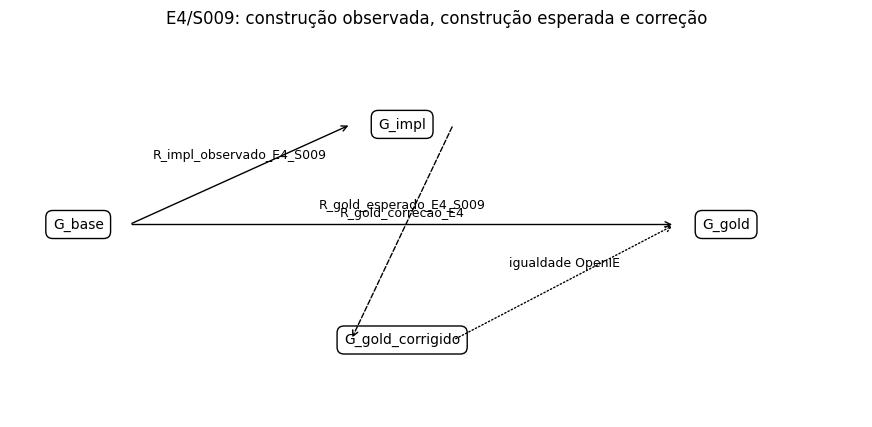

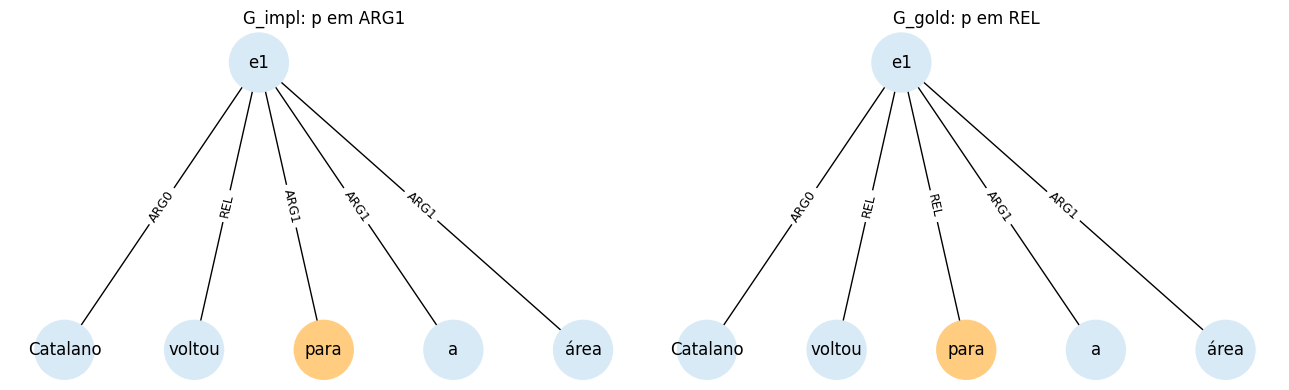

In [14]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.axis("off")
caixas = {
    "G_base": (0.08, 0.50),
    "G_impl": (0.46, 0.76),
    "G_gold": (0.84, 0.50),
    "G_gold_corrigido": (0.46, 0.20),
}
for rotulo, (x, y) in caixas.items():
    ax.text(
        x,
        y,
        rotulo,
        ha="center",
        va="center",
        bbox={"boxstyle": "round,pad=0.5", "fc": "white", "ec": "black"},
        transform=ax.transAxes,
    )

def seta(origem, destino, texto, estilo="-"):
    x1, y1 = caixas[origem]
    x2, y2 = caixas[destino]
    ax.annotate(
        "",
        xy=(x2 - 0.06, y2),
        xytext=(x1 + 0.06, y1),
        xycoords=ax.transAxes,
        arrowprops={"arrowstyle": "->", "linestyle": estilo},
    )
    ax.text(
        (x1 + x2) / 2,
        (y1 + y2) / 2 + 0.04,
        texto,
        ha="center",
        fontsize=9,
        transform=ax.transAxes,
    )

seta("G_base", "G_impl", REGRA_IMPL_NOME)
seta("G_base", "G_gold", REGRA_GOLD_NOME)
seta("G_impl", "G_gold_corrigido", REGRA_CORRECAO_NOME, "--")
seta("G_gold_corrigido", "G_gold", "igualdade OpenIE", ":")
ax.set_title("E4/S009: construção observada, construção esperada e correção")
plt.show()


def desenhar_estado_openie(ax, grafo, titulo, destaque):
    sub = nx.DiGraph()
    for origem, destino, dados in grafo.edges(data=True):
        if dados.get("camada") == OPENIE:
            sub.add_edge(origem, destino, rel=dados["rel"])
    pos = {"e1": (0, 0)}
    posicoes_tokens = {"t1": (-1.2, -1), "t2": (-0.4, -1), "t3": (0.4, -1),
                       "t4": (1.2, -1), "t5": (2.0, -1)}
    for no in sub.nodes:
        if no != "e1":
            pos[no] = posicoes_tokens[no]
    cores = ["#ffcc80" if no == destaque else "#d9eaf7" for no in sub.nodes]
    nx.draw_networkx_nodes(sub, pos, node_color=cores, node_size=1800, ax=ax)
    nx.draw_networkx_labels(
        sub,
        pos,
        labels={
            no: ("e1" if no == "e1" else grafo.nodes[no]["form"])
            for no in sub.nodes
        },
        ax=ax,
    )
    nx.draw_networkx_edges(sub, pos, arrows=True, ax=ax)
    nx.draw_networkx_edge_labels(
        sub,
        pos,
        edge_labels=nx.get_edge_attributes(sub, "rel"),
        ax=ax,
        font_size=9,
    )
    ax.set_title(titulo)
    ax.axis("off")


fig, axes = plt.subplots(1, 2, figsize=(13, 4))
desenhar_estado_openie(axes[0], G_impl, "G_impl: p em ARG1", "t3")
desenhar_estado_openie(axes[1], G_gold, "G_gold: p em REL", "t3")
plt.tight_layout()
plt.show()

# 15. Proveniência, limitações e registro final

## Proveniência preservada

- Catalano foi selecionado como sujeito.
- voltou foi inicializado e permaneceu como núcleo de REL.
- para não foi visitado na travessia observada de construção de REL.
- área iniciou a concatenação do argumento.
- a instância do intervalo 3–5 adicionou para, a e área.
- o mesmo objeto de argumento apareceu como ARG2 da extração piloto.

## Limitações

- R_impl_observado_E4_S009 descreve somente a instância observada S009.
- O trace não demonstra que todo case seja enviado a ARG1.
- case não é tratado como condição operacional de inclusão.
- A ausência de visita de para não é representada como rejeição.
- Rege é conhecimento linguístico da regra esperada, não guarda comprovada da
  implementação observada.
- nsubj permanece contexto/proveniência e não guarda específica da divergência.
- O intervalo concreto 3–5 é evidência da instância; a regra usa I(p,n).
- A modelagem não constitui correção, Theory Revision ou regra geral do DptOIE.

In [15]:
REGISTRO_FINAL = {
    "NOTEBOOK_CREATED": "research/graph_rewriting/experimento_v2_e4_impl_gold.ipynb",
    "G_BASE": estado_openie(G_base),
    "R_IMPL_RESULT": estado_openie(G_impl),
    "R_GOLD_EXPECTED_RESULT": estado_openie(G_gold),
    "RULE_DIFF": DIFF_REGRAS,
    "STATE_DIFF": DIFF_ESTADOS,
    "CORRECTION_VALIDATION": (
        assinatura_openie(G_gold_corrigido) == assinatura_openie(G_gold)
    ),
    "ASSERTIONS": "PASS",
    "LIMITATIONS": [
        "somente E4/S009",
        "sem generalização para todo o DptOIE",
        "sem Theory Revision",
        "sem proposta de R'_impl",
    ],
}

for chave, valor in REGISTRO_FINAL.items():
    print(f"{chave}: {valor}")

NOTEBOOK_CREATED: research/graph_rewriting/experimento_v2_e4_impl_gold.ipynb
G_BASE: (('ARG0', ('Catalano',)), ('REL', ()), ('ARG1', ()))
R_IMPL_RESULT: (('ARG0', ('Catalano',)), ('REL', ('voltou',)), ('ARG1', ('para', 'a', 'área')))
R_GOLD_EXPECTED_RESULT: (('ARG0', ('Catalano',)), ('REL', ('voltou', 'para')), ('ARG1', ('a', 'área')))
RULE_DIFF: {'contexto_comum': ['CandidatoNucleoREL(e,v)', 'Extracao(e)', 'dep(d,n,det)', 'dep(n,v,nmod)', 'dep(p,n,case)'], 'guardas_comuns': ['OPERACIONAL:CandidatoNucleoREL(e,v)'], 'guardas_somente_impl': ['OPERACIONAL:I(p,n) disponível', 'OPERACIONAL:filho(p,n)', 'OPERACIONAL:nmod(n,v)', 'OPERACIONAL:ordem(p)<ordem(n)'], 'guardas_somente_gold': ['LINGUISTICA:Rege(v,p)'], 'efeitos_comuns': ['ARG1(e,d)', 'ARG1(e,n)', 'REL(e,v)'], 'efeitos_somente_impl': ['ARG1(e,p)'], 'efeitos_somente_gold': ['REL(e,p)'], 'conflitos_de_componente': [{'elemento': 'p', 'impl': ['ARG1'], 'gold': ['REL']}], 'proveniencia_impl': ['REL final observado: [v]', 'p não visitado n